# Ablation study

## Installation

In [ ]:
import subprocess, sys

def _pip(*args):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=False)

_pip("nibabel", "opencv-python-headless", "scipy", "pandas", "matplotlib", "tqdm")

INSTALL_MAMBA_SSM = True
if INSTALL_MAMBA_SSM:
    try:
        from mamba_ssm import Mamba  # noqa: F401
        print("mamba_ssm already available")
    except Exception:
        import torch
        print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| python", sys.version.split()[0])
        _pip("packaging", "ninja", "wheel")
        logs = []
        for pkg in ["causal-conv1d>=1.4.0", "mamba-ssm"]:
            r = subprocess.run([sys.executable, "-m", "pip", "install", pkg, "--no-build-isolation"],
                               capture_output=True, text=True)
            logs.append((pkg, r.returncode, r.stdout[-1500:] + r.stderr[-1500:]))
        try:
            from mamba_ssm import Mamba  # noqa: F401
            print("mamba_ssm installed successfully")
        except Exception as e:
            print("mamba_ssm could NOT be installed -> the exact PyTorch fallback scan will be used (slower).")
            print("Import error:", repr(e))
            for pkg, code, log in logs:
                print(f"\n--- pip install {pkg} (exit {code}) ---\n{log}")

## Imports and configuration

In [ ]:
import os, re, glob, json, math, time, random, copy, warnings, zipfile
import numpy as np
import pandas as pd
import cv2
import nibabel as nib
import matplotlib
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.ndimage import binary_erosion, distance_transform_edt, generate_binary_structure

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint
from torchvision.ops import DeformConv2d

warnings.filterwarnings("ignore", category=UserWarning)

try:
    from mamba_ssm import Mamba as MambaCUDA
    HAS_MAMBA_SSM = True
except Exception as _e:
    HAS_MAMBA_SSM = False
    print("mamba_ssm not usable:", repr(_e))

#  Google Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

CFG = dict(
    ZIP_PATHS=["/content/liver-tumor-segmentation.zip", "/content/liver-tumor-segmentation-part-2.zip"],
    DOWNLOAD_FROM_KAGGLE=True,
    KAGGLE_DATASETS=["andrewmvd/liver-tumor-segmentation", "andrewmvd/liver-tumor-segmentation-part-2"],
    # Pre-processed slices
    CACHE_DIR="/content/LiTS_cache_256",
    CACHE_BACKUP_ZIP="",
    DELETE_ZIP_AFTER_CACHE=False,
    OUT_DIR="/content/drive/MyDrive/UMamba_DLKA_ARO_outputs",

    # data
    SEED=42,
    N_TRAIN=92, N_VAL=13, N_TEST=26,
    HU_MIN=-150.0, HU_MAX=250.0,
    IMG_SIZE=256,
    EMPTY_SLICE_FRACTION=0.10,
    NUM_WORKERS=2,

    # augmentation (training only)
    AUG_HFLIP_P=0.5, AUG_ROT_DEG=15.0, AUG_SCALE=(0.9, 1.1), AUG_TRANSLATE=0.10,

    # architecture
    CHANNELS=(32, 64, 128, 256, 320),
    D_STATE=16, D_CONV=4, EXPAND=2,
    SCAN_CHUNK=256,

    #  ARO
    RUN_ARO=True,
    ARO_POP=20, ARO_MAX_ITER=30, ARO_PATIENCE=5,
    ARO_EPOCHS=20, ARO_SEEDS=(42, 43, 44),
    LR_RANGE=(1e-5, 1e-3), DROPOUT_RANGE=(0.10, 0.50), WD_RANGE=(1e-6, 1e-3),
    BATCH_CHOICES=(8, 16, 32),
    ARO_TRAIN_FRACTION=1.0,
    DEFAULT_HP=dict(lr=1e-4, dropout=0.20, weight_decay=1e-4, batch_size=16),

    #  final training
    EPOCHS=100,
    USE_AMP=True,
    THRESHOLD=0.5,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs(CFG["OUT_DIR"], exist_ok=True)
os.makedirs(CFG["CACHE_DIR"], exist_ok=True)
print(f"Device: {DEVICE} | mamba_ssm CUDA kernels: {HAS_MAMBA_SSM} | Colab: {IN_COLAB}")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


seed_everything(CFG["SEED"])

Mounted at /content/drive
Device: cuda | mamba_ssm CUDA kernels: True | Colab: True
GPU: Tesla T4


## Dataset acquisition

In [ ]:
import subprocess
import sys
import glob
import os
import json
import zipfile
import re

def _pip(*args):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=False)

if CFG["CACHE_BACKUP_ZIP"] and os.path.exists(CFG["CACHE_BACKUP_ZIP"]) and not glob.glob(os.path.join(CFG["CACHE_DIR"], "*.npz")):
    print("Restoring the preprocessed cache from", CFG["CACHE_BACKUP_ZIP"])
    subprocess.run(["unzip", "-q", "-o", CFG["CACHE_BACKUP_ZIP"], "-d", CFG["CACHE_DIR"]], check=True)


def cache_complete():
    marker = os.path.join(CFG["CACHE_DIR"], "index.json")
    if not os.path.exists(marker):
        return False
    cases = json.load(open(marker))["cases"]
    expected = CFG["N_TRAIN"] + CFG["N_VAL"] + CFG["N_TEST"]          # 131 annotated LiTS volumes
    return len(cases) >= expected and all(
        os.path.exists(os.path.join(CFG["CACHE_DIR"], f"case_{c:03d}.npz")) for c in cases)


def get_dataset_zips():

    for zp, ds in zip(CFG["ZIP_PATHS"], CFG["KAGGLE_DATASETS"]):
        if os.path.exists(zp):
            continue
        assert CFG["DOWNLOAD_FROM_KAGGLE"], f"Zip not found: {zp}"
        if not os.environ.get("KAGGLE_API_TOKEN") and not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")):
            from getpass import getpass
            os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your Kaggle API token and press Enter: ").strip()
        _pip("-U", "kaggle")
        print(f"Downloading {ds} from Kaggle into /content ...")
        subprocess.run(["kaggle", "datasets", "download", "-d", ds, "-p", os.path.dirname(zp)], check=True)
    extra = [p for p in glob.glob("/content/*.zip") if p not in CFG["ZIP_PATHS"] and "cache" not in p.lower()]
    return [p for p in CFG["ZIP_PATHS"] if os.path.exists(p)] + extra


def index_zips(zip_paths):

    vols, segs = {}, {}
    for zp in zip_paths:
        for n in zipfile.ZipFile(zp).namelist():
            b = os.path.basename(n)
            m = re.match(r"volume-(\d+)\.nii(\.gz)?$", b)
            if m:
                vols[int(m.group(1))] = (zp, n)
            m = re.match(r"segmentation-(\d+)\.nii(\.gz)?$", b)
            if m:
                segs[int(m.group(1))] = (zp, n)
    missing = sorted(set(segs) - set(vols))
    if missing:
        print(f"{len(missing)} segmentations have no CT volume in the zips (e.g. {missing[:5]}) - "
              "download liver-tumor-segmentation-part-2.")
    return sorted(set(vols) & set(segs)), vols, segs


if cache_complete():
    CASE_IDS = json.load(open(os.path.join(CFG["CACHE_DIR"], "index.json")))["cases"]
    DATA_ZIPS = []
    print("Preprocessed cache found - dataset zips not needed.")
else:
    DATA_ZIPS = get_dataset_zips()
    print("Dataset zips:", DATA_ZIPS)
    CASE_IDS, VOL_MEMBERS, SEG_MEMBERS = index_zips(DATA_ZIPS)
print(f"Annotated CT volumes found: {len(CASE_IDS)}")
if len(CASE_IDS) != 131:
    print("WARNING: expected 131 annotated LiTS volumes - check the zip.")
HD_UNIT = "mm"
HD_COL = f"HD95 ({HD_UNIT})"

Dataset zips: ['/content/liver-tumor-segmentation.zip', '/content/liver-tumor-segmentation-part-2.zip']
Annotated CT volumes found: 131


## Preprocessing

In [ ]:
def hu_window_normalise(x, lo=CFG["HU_MIN"], hi=CFG["HU_MAX"]):
    x = np.clip(x, lo, hi)
    return (x - lo) / (hi - lo)


def preprocess_slice(ct_slice, size=CFG["IMG_SIZE"]):
    img = hu_window_normalise(ct_slice).astype(np.float32)
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_LINEAR)


def resize_mask(mask_slice, size=CFG["IMG_SIZE"]):
    return cv2.resize(mask_slice.astype(np.uint8), (size, size), interpolation=cv2.INTER_NEAREST)


def load_raw_volume(zfs, case_id, tmp_dir="/content/_nii_tmp" if IN_COLAB else "_nii_tmp"):
    os.makedirs(tmp_dir, exist_ok=True)
    vz, vm = VOL_MEMBERS[case_id]
    sz, sm = SEG_MEMBERS[case_id]
    vp = zfs[vz].extract(vm, tmp_dir)
    sp = zfs[sz].extract(sm, tmp_dir)
    vimg = nib.load(vp)
    ct = vimg.get_fdata(dtype=np.float32)
    liver = (np.asanyarray(nib.load(sp).dataobj) > 0).astype(np.uint8)   # liver label includes tumour (1 and 2)
    spacing = tuple(float(s) for s in vimg.header.get_zooms()[:3])
    os.remove(vp); os.remove(sp)
    return ct, liver, spacing


def cache_case(zfs, case_id):
    path = os.path.join(CFG["CACHE_DIR"], f"case_{case_id:03d}.npz")
    if os.path.exists(path):
        return path
    ct, liver, spacing = load_raw_volume(zfs, case_id)
    n = ct.shape[2]
    imgs = np.empty((n, CFG["IMG_SIZE"], CFG["IMG_SIZE"]), np.uint8)
    msks = np.empty_like(imgs)
    for k in range(n):
        imgs[k] = np.round(preprocess_slice(ct[:, :, k]) * 255).astype(np.uint8)
        msks[k] = resize_mask(liver[:, :, k])
    tmp = path.replace(".npz", "_tmp.npz")
    np.savez_compressed(tmp, img=imgs, msk=msks, has_liver=liver.reshape(-1, n).any(0),
                        gt_orig=np.packbits(liver.astype(bool)), shape=np.array(liver.shape),
                        spacing=np.array(spacing))
    os.replace(tmp, path)
    return path


if not cache_complete():
    os.makedirs(CFG["CACHE_DIR"], exist_ok=True)
    zfs = {p: zipfile.ZipFile(p) for p in DATA_ZIPS}
    for cid in tqdm(CASE_IDS, desc="Pre-processing all CT volumes"):
        cache_case(zfs, cid)
    for z_ in zfs.values():
        z_.close()
    json.dump(dict(cases=CASE_IDS), open(os.path.join(CFG["CACHE_DIR"], "index.json"), "w"))
    if CFG["CACHE_BACKUP_ZIP"]:
        subprocess.run(["zip", "-q", "-r", "-0", CFG["CACHE_BACKUP_ZIP"], "."], cwd=CFG["CACHE_DIR"], check=True)
        print("Cache backed up to", CFG["CACHE_BACKUP_ZIP"])
    if CFG["DELETE_ZIP_AFTER_CACHE"]:
        for p in DATA_ZIPS:
            if p.startswith("/content/"):
                os.remove(p); print("Deleted", p)


def load_volume(case_id):
    d = np.load(os.path.join(CFG["CACHE_DIR"], f"case_{case_id:03d}.npz"))
    shape = tuple(int(v) for v in d["shape"])
    gt = np.unpackbits(d["gt_orig"])[:int(np.prod(shape))].reshape(shape).astype(np.uint8)
    imgs = np.transpose(d["img"], (1, 2, 0)).astype(np.float32) / 255.0
    return imgs, gt, tuple(float(s) for s in d["spacing"])


def display_slice(ct, k, hw):
    return cv2.resize(ct[:, :, k], (hw[1], hw[0]), interpolation=cv2.INTER_LINEAR)

Pre-processing all CT volumes:   0%|          | 0/131 [00:00<?, ?it/s]

## Dataset splitting

In [ ]:
split_path = os.path.join(CFG["OUT_DIR"], "split.json")
SPLIT = json.load(open(split_path)) if os.path.exists(split_path) else None
if SPLIT is None or sorted(SPLIT["train"] + SPLIT["val"] + SPLIT["test"]) != sorted(CASE_IDS):
    if SPLIT is not None:
        print("Saved split does not match the 131 volumes found - creating a new split.")
    rng = np.random.RandomState(CFG["SEED"])
    perm = [int(i) for i in rng.permutation(CASE_IDS)]
    n_tr, n_va = CFG["N_TRAIN"], CFG["N_VAL"]
    if len(perm) != n_tr + n_va + CFG["N_TEST"]:
        n_tr = int(round(0.70 * len(perm))); n_va = int(round(0.10 * len(perm)))
    SPLIT = dict(train=sorted(perm[:n_tr]), val=sorted(perm[n_tr:n_tr + n_va]), test=sorted(perm[n_tr + n_va:]))
    json.dump(SPLIT, open(split_path, "w"), indent=1)
print({k: len(v) for k, v in SPLIT.items()})
assert not (set(SPLIT["train"]) & set(SPLIT["val"]) or set(SPLIT["train"]) & set(SPLIT["test"])
            or set(SPLIT["val"]) & set(SPLIT["test"])), "patient leakage between subsets"

{'train': 92, 'val': 13, 'test': 26}


## Slice datasets and augmentation (training subset only)

SPLIT was empty. Re-generating random splits...
New split generated: {'train': 92, 'val': 13, 'test': 26}
Training slices: 16152 | Validation slices: 1883


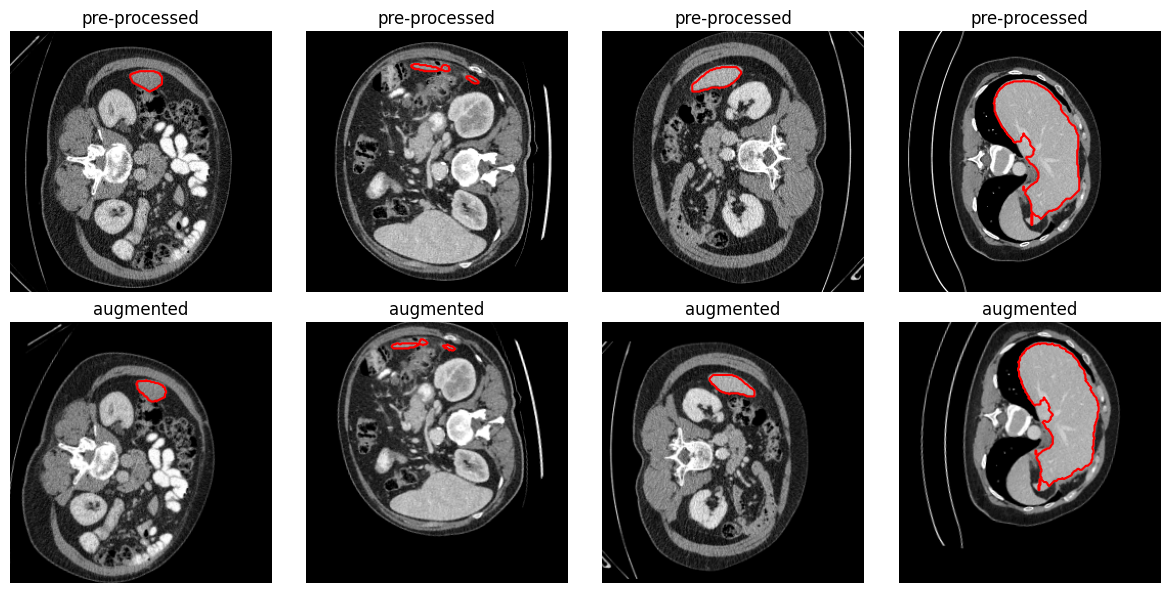

In [ ]:
import os
import random
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

if not SPLIT.get("train"):
    print("SPLIT was empty. Re-generating random splits...")
    rng = np.random.RandomState(CFG["SEED"])
    perm = [int(i) for i in rng.permutation(CASE_IDS)]
    n_tr, n_va = CFG["N_TRAIN"], CFG["N_VAL"]
    if len(perm) != n_tr + n_va + CFG["N_TEST"]:
        n_tr = int(round(0.70 * len(perm))); n_va = int(round(0.10 * len(perm)))
    SPLIT = dict(train=sorted(perm[:n_tr]), val=sorted(perm[n_tr:n_tr + n_va]), test=sorted(perm[n_tr + n_va:]))
    import json
    json.dump(SPLIT, open(split_path, "w"), indent=1)
    print("New split generated:", {k: len(v) for k, v in SPLIT.items()})

def gather_slices(case_ids, empty_fraction, seed, sample_fraction=1.0):
    rng = np.random.RandomState(seed)
    X, Y = [], []
    for cid in case_ids:
        d = np.load(os.path.join(CFG["CACHE_DIR"], f"case_{cid:03d}.npz"))
        has = d["has_liver"]
        keep = has | (rng.rand(len(has)) < empty_fraction)
        if sample_fraction < 1.0:
            keep &= rng.rand(len(has)) < sample_fraction
        X.append(d["img"][keep]); Y.append(d["msk"][keep])
    return np.concatenate(X), np.concatenate(Y)


class LiverSliceDataset(Dataset):
    def __init__(self, images, masks, augment=False):
        self.images, self.masks, self.augment = images, masks, augment

    def __len__(self):
        return len(self.images)

    def _augment(self, img, msk):
        s = img.shape[0]
        if random.random() < CFG["AUG_HFLIP_P"]:
            img, msk = img[:, ::-1], msk[:, ::-1]
        ang = random.uniform(-CFG["AUG_ROT_DEG"], CFG["AUG_ROT_DEG"])
        sc = random.uniform(*CFG["AUG_SCALE"])
        tx, ty = (random.uniform(-CFG["AUG_TRANSLATE"], CFG["AUG_TRANSLATE"]) * s for _ in range(2))
        M = cv2.getRotationMatrix2D((s / 2, s / 2), ang, sc)
        M[:, 2] += (tx, ty)
        img = cv2.warpAffine(np.ascontiguousarray(img), M, (s, s), flags=cv2.INTER_LINEAR,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        msk = cv2.warpAffine(np.ascontiguousarray(msk), M, (s, s), flags=cv2.INTER_NEAREST,
                             borderMode=cv2.BORDER_CONSTANT, borderValue=0)
        return img, msk

    def __getitem__(self, i):
        img = self.images[i].astype(np.float32) / 255.0
        msk = self.masks[i].astype(np.float32)
        if self.augment:
            img, msk = self._augment(img, msk)
        return (torch.from_numpy(np.ascontiguousarray(img))[None],
                torch.from_numpy(np.ascontiguousarray(msk))[None])


TRAIN_X, TRAIN_Y = gather_slices(SPLIT["train"], CFG["EMPTY_SLICE_FRACTION"], CFG["SEED"])
VAL_X, VAL_Y = gather_slices(SPLIT["val"], CFG["EMPTY_SLICE_FRACTION"], CFG["SEED"] + 1)
print(f"Training slices: {len(TRAIN_X)} | Validation slices: {len(VAL_X)}")


def make_loader(x, y, batch_size, train):
    ds = LiverSliceDataset(x, y, augment=train)
    return DataLoader(ds, batch_size=batch_size, shuffle=train, drop_last=train and len(ds) > batch_size,
                      num_workers=CFG["NUM_WORKERS"], pin_memory=DEVICE.type == "cuda",
                      persistent_workers=CFG["NUM_WORKERS"] > 0)


# visual check of preprocessing + augmentation
_ds = LiverSliceDataset(TRAIN_X, TRAIN_Y, augment=True)
_idx = np.random.RandomState(0).choice(np.where(TRAIN_Y.reshape(len(TRAIN_Y), -1).any(1))[0], 4)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for j, i in enumerate(_idx):
    im, m = _ds[i]
    ax[0, j].imshow(TRAIN_X[i], cmap="gray"); ax[0, j].contour(TRAIN_Y[i], [0.5], colors="r"); ax[0, j].set_title("pre-processed")
    ax[1, j].imshow(im[0], cmap="gray"); ax[1, j].contour(m[0].numpy(), [0.5], colors="r"); ax[1, j].set_title("augmented")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(CFG["OUT_DIR"], "preprocessing_augmentation.png"), dpi=150); plt.show()

## Model: U-Mamba encoder + DLKA + U-Net decoder

### Selective state-space model (Mamba)


In [ ]:
def _scan_chunk(x, dt, A, Bm, Cm, h0):

    tiny = 1e-30
    S = torch.cumsum(dt.unsqueeze(-1) * A, dim=1)
    u = (dt * x).unsqueeze(-1) * Bm.unsqueeze(2)
    lp = torch.log(u.clamp(min=0) + tiny) - S
    ln = torch.log((-u).clamp(min=0) + tiny) - S
    lp0 = torch.log(h0.clamp(min=0) + tiny).unsqueeze(1)
    ln0 = torch.log((-h0).clamp(min=0) + tiny).unsqueeze(1)
    Lp = torch.logcumsumexp(torch.cat([lp0, lp], 1), dim=1)[:, 1:]
    Ln = torch.logcumsumexp(torch.cat([ln0, ln], 1), dim=1)[:, 1:]
    h = torch.exp(S + Lp) - torch.exp(S + Ln)
    y = (h * Cm.unsqueeze(2)).sum(-1)                             #
    return y, h[:, -1]


def selective_scan(x, dt, A, Bm, Cm, Dskip, chunk):
    Bsz, L, D = x.shape
    h = x.new_zeros(Bsz, D, A.shape[1])
    ys = []
    for s in range(0, L, chunk):
        args = (x[:, s:s + chunk], dt[:, s:s + chunk], A, Bm[:, s:s + chunk], Cm[:, s:s + chunk], h)
        if torch.is_grad_enabled():
            y, h = checkpoint(_scan_chunk, *args, use_reentrant=False)
        else:
            y, h = _scan_chunk(*args)
        ys.append(y)
    return torch.cat(ys, 1) + x * Dskip


class MambaTorch(nn.Module):
    def __init__(self, d_model, d_state=16, d_conv=4, expand=2, chunk=256,
                 dt_min=1e-3, dt_max=0.1, dt_init_floor=1e-4):
        super().__init__()
        self.d_inner, self.d_state, self.chunk = expand * d_model, d_state, chunk
        self.dt_rank = math.ceil(d_model / 16)
        self.in_proj = nn.Linear(d_model, 2 * self.d_inner, bias=False)
        self.conv1d = nn.Conv1d(self.d_inner, self.d_inner, d_conv, groups=self.d_inner, padding=d_conv - 1)
        self.x_proj = nn.Linear(self.d_inner, self.dt_rank + 2 * d_state, bias=False)
        self.dt_proj = nn.Linear(self.dt_rank, self.d_inner, bias=True)
        dt = torch.exp(torch.rand(self.d_inner) * (math.log(dt_max) - math.log(dt_min)) + math.log(dt_min))
        dt = dt.clamp(min=dt_init_floor)
        with torch.no_grad():
            self.dt_proj.bias.copy_(dt + torch.log(-torch.expm1(-dt)))
        self.A_log = nn.Parameter(torch.log(torch.arange(1, d_state + 1).float().repeat(self.d_inner, 1)))
        self.D = nn.Parameter(torch.ones(self.d_inner))
        self.out_proj = nn.Linear(self.d_inner, d_model, bias=False)

    def forward(self, u):
        L = u.shape[1]
        x, z = self.in_proj(u).chunk(2, dim=-1)
        x = F.silu(self.conv1d(x.transpose(1, 2))[..., :L].transpose(1, 2))
        dt, Bm, Cm = torch.split(self.x_proj(x), [self.dt_rank, self.d_state, self.d_state], dim=-1)
        dt = F.softplus(self.dt_proj(dt))
        A = -torch.exp(self.A_log.float())
        with torch.autocast(device_type=u.device.type, enabled=False):
            y = selective_scan(x.float(), dt.float(), A, Bm.float(), Cm.float(), self.D.float(), self.chunk)
        y = y.to(z.dtype) * F.silu(z)
        return self.out_proj(y)


def make_mamba(dim):
    if HAS_MAMBA_SSM and DEVICE.type == "cuda":
        return MambaCUDA(d_model=dim, d_state=CFG["D_STATE"], d_conv=CFG["D_CONV"], expand=CFG["EXPAND"])
    return MambaTorch(dim, CFG["D_STATE"], CFG["D_CONV"], CFG["EXPAND"], chunk=CFG["SCAN_CHUNK"])

### U-Mamba encoder

In [ ]:
class ConvBNReLU(nn.Sequential):
    def __init__(self, cin, cout, k=3, stride=1):
        super().__init__(nn.Conv2d(cin, cout, k, stride, k // 2, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))


class ResConvBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = ConvBNReLU(cin, cout, 3, stride)
        self.conv2 = nn.Sequential(nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout))
        self.skip = (nn.Identity() if (cin == cout and stride == 1) else
                     nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout)))

    def forward(self, x):
        return F.relu(self.conv2(self.conv1(x)) + self.skip(x))


class UMambaBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.mamba = make_mamba(dim)

    def forward(self, x):
        B, C, H, W = x.shape
        t = x.flatten(2).transpose(1, 2).float()
        out = self.mamba(self.norm(t))
        out = out.transpose(1, 2).reshape(B, C, H, W).to(x.dtype)
        return x + out


class UMambaEncoder(nn.Module):
    def __init__(self, in_ch, chs):
        super().__init__()
        self.stem = ConvBNReLU(in_ch, chs[0])
        self.stages = nn.ModuleList([
            nn.Sequential(ResConvBlock(chs[i], chs[i + 1], stride=2), UMambaBlock(chs[i + 1]))
            for i in range(4)])

    def forward(self, x):
        feats = [self.stem(x)]
        for st in self.stages:
            feats.append(st(feats[-1]))
        return feats[:-1], feats[-1]

### Deformable Large Kernel Attention (bottleneck)

In [ ]:
class DeformableDWConv(nn.Module):
    def __init__(self, dim, k, dilation=1):
        super().__init__()
        pad = dilation * (k - 1) // 2
        self.offset = nn.Conv2d(dim, 2 * k * k, k, padding=pad, dilation=dilation)
        nn.init.zeros_(self.offset.weight); nn.init.zeros_(self.offset.bias)
        self.conv = DeformConv2d(dim, dim, k, padding=pad, dilation=dilation, groups=dim)

    def forward(self, x):
        return self.conv(x, self.offset(x))


class DeformableLKA(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.ddw = DeformableDWConv(dim, 5)
        self.ddwd = DeformableDWConv(dim, 7, dilation=3)
        self.pw = nn.Conv2d(dim, dim, 1)

    def forward(self, x):
        return x * self.pw(self.ddwd(self.ddw(x)))


class DLKABlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.norm = nn.BatchNorm2d(dim)
        self.proj1 = nn.Conv2d(dim, dim, 1)
        self.act = nn.GELU()
        self.lka = DeformableLKA(dim)
        self.proj2 = nn.Conv2d(dim, dim, 1)

    def forward(self, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            x = x.float()
            return x + self.proj2(self.lka(self.act(self.proj1(self.norm(x)))))

### U-Net decoder and full network

In [ ]:
class DecoderStage(nn.Module):

    def __init__(self, cin, cskip, cout, dropout):
        super().__init__()
        self.up = nn.ConvTranspose2d(cin, cout, 2, stride=2)
        self.conv = nn.Sequential(ConvBNReLU(cout + cskip, cout), ConvBNReLU(cout, cout))
        self.drop = nn.Dropout2d(dropout)

    def forward(self, x, skip):
        return self.drop(self.conv(torch.cat([skip, self.up(x)], dim=1)))


class UMambaDLKA(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, chs=CFG["CHANNELS"], dropout=0.2, use_dlka=True):
        super().__init__()
        self.encoder = UMambaEncoder(in_ch, chs)
        self.dlka = DLKABlock(chs[4]) if use_dlka else nn.Identity()
        self.drop = nn.Dropout2d(dropout)
        self.decoder = nn.ModuleList([DecoderStage(chs[i + 1], chs[i], chs[i], dropout) for i in reversed(range(4))])
        self.head = nn.Conv2d(chs[0], out_ch, 1)

    def forward(self, x):
        skips, x = self.encoder(x)
        x = self.drop(self.dlka(x))
        for dec, skip in zip(self.decoder, reversed(skips)):
            x = dec(x, skip)
        return self.head(x)


_m = UMambaDLKA().to(DEVICE)
with torch.no_grad():
    print("Output shape:", _m(torch.zeros(2, 1, CFG["IMG_SIZE"], CFG["IMG_SIZE"], device=DEVICE)).shape)
print(f"Trainable parameters: {sum(p.numel() for p in _m.parameters() if p.requires_grad) / 1e6:.2f} M")
del _m

Output shape: torch.Size([2, 1, 256, 256])
Trainable parameters: 9.34 M


## Loss, metrics and training routine

In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, target):
        logits = logits.float()
        p = torch.sigmoid(logits)
        inter = (p * target).sum()
        dice = 1 - (2 * inter + self.smooth) / (p.sum() + target.sum() + self.smooth)
        return dice + self.bce(logits, target)


def counts(pred_bin, target):
    tp = (pred_bin & target).sum().item()
    fp = (pred_bin & ~target).sum().item()
    fn = (~pred_bin & target).sum().item()
    return tp, fp, fn


def metrics_from_counts(tp, fp, fn, eps=1e-8):
    return dict(DSC=2 * tp / (2 * tp + fp + fn + eps), IoU=tp / (tp + fp + fn + eps),
                Precision=tp / (tp + fp + eps), Recall=tp / (tp + fn + eps))


def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, n, TP, FP, FN = 0.0, 0, 0, 0, 0
    with torch.set_grad_enabled(train):
        for img, msk in loader:
            img = img.to(DEVICE, non_blocking=True); msk = msk.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=CFG["USE_AMP"] and DEVICE.type == "cuda"):
                logits = model(img)
            loss = criterion(logits, msk)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer); scaler.update()
            tot_loss += loss.item() * img.size(0); n += img.size(0)
            tp, fp, fn = counts(torch.sigmoid(logits.float()) > CFG["THRESHOLD"], msk > 0.5)
            TP += tp; FP += fp; FN += fn
    return tot_loss / max(n, 1), metrics_from_counts(TP, FP, FN)["DSC"]


def train_model(hp, epochs, train_xy, val_xy, seed=42, ckpt_path=None, verbose=True, use_dlka=True):
    seed_everything(seed)
    model = UMambaDLKA(dropout=hp["dropout"], use_dlka=use_dlka).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    scaler = torch.amp.GradScaler("cuda", enabled=CFG["USE_AMP"] and DEVICE.type == "cuda")
    criterion = DiceBCELoss()
    tr_loader = make_loader(*train_xy, hp["batch_size"], train=True)
    va_loader = make_loader(*val_xy, hp["batch_size"], train=False)
    hist, start, best_dsc = [], 0, -1.0
    if ckpt_path and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optim"]); scaler.load_state_dict(ck["scaler"])
        hist, start, best_dsc = ck["hist"], ck["epoch"] + 1, ck["best_dsc"]
        print(f"Resumed from epoch {start}")
    for ep in range(start, epochs):
        t0 = time.time()
        tr_loss, tr_dsc = run_epoch(model, tr_loader, criterion, optimizer, scaler)
        va_loss, va_dsc = run_epoch(model, va_loader, criterion)
        hist.append(dict(epoch=ep + 1, train_loss=tr_loss, val_loss=va_loss, train_dsc=tr_dsc, val_dsc=va_dsc))
        if verbose:
            print(f"Epoch {ep + 1:3d}/{epochs} | train loss {tr_loss:.4f} DSC {tr_dsc:.4f} | "
                  f"val loss {va_loss:.4f} DSC {va_dsc:.4f} | {time.time() - t0:.0f}s")
        if ckpt_path:
            if va_dsc > best_dsc:
                best_dsc = va_dsc
                torch.save(model.state_dict(), ckpt_path.replace(".pt", "_best.pt"))
            torch.save(dict(model=model.state_dict(), optim=optimizer.state_dict(), scaler=scaler.state_dict(),
                            hist=hist, epoch=ep, best_dsc=best_dsc), ckpt_path)
    return model, hist

In [ ]:

def hd95(pred, gt, spacing):
    if not pred.any() and not gt.any():
        return 0.0
    if not pred.any() or not gt.any():
        return float("nan")
    idx = np.argwhere(pred | gt)
    lo = np.maximum(idx.min(0) - 2, 0); hi = idx.max(0) + 3
    p = pred[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]; g = gt[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
    st = generate_binary_structure(3, 1)
    ps = p ^ binary_erosion(p, st)
    gs = g ^ binary_erosion(g, st)
    d_pg = distance_transform_edt(~gs, sampling=spacing)[ps]
    d_gp = distance_transform_edt(~ps, sampling=spacing)[gs]
    return float(np.percentile(np.concatenate([d_pg, d_gp]), 95))


@torch.no_grad()
def predict_volume(model, ct, out_hw, batch=32):
    (H, W), S = out_hw, ct.shape[2]
    pred = np.zeros((H, W, S), dtype=bool)
    for s0 in range(0, S, batch):
        imgs = np.stack([ct[:, :, k] for k in range(s0, min(s0 + batch, S))]).astype(np.float32)
        x = torch.from_numpy(imgs)[:, None].to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, enabled=CFG["USE_AMP"] and DEVICE.type == "cuda"):
            prob = torch.sigmoid(model(x).float())[:, 0].cpu().numpy()
        for j, k in enumerate(range(s0, s0 + len(imgs))):
            pred[:, :, k] = cv2.resize(prob[j], (W, H), interpolation=cv2.INTER_LINEAR) > CFG["THRESHOLD"]
    return pred

## Ablation configurations



In [ ]:

HP = dict(lr=1e-3, dropout=0.10, weight_decay=1e-5, batch_size=8)

ABL_DIR = os.path.join(CFG["OUT_DIR"], "ablation")
os.makedirs(ABL_DIR, exist_ok=True)

ABLATIONS = [
    dict(name="U-Mamba Encoder + U-Net Decoder (Baseline)", tag="baseline_umamba_unet",
         use_dlka=False, hp=HP, ckpt=os.path.join(ABL_DIR, "baseline_umamba_unet.pt")),
    dict(name="U-Mamba Encoder + DLKA + U-Net Decoder (Without ARO)", tag="umamba_dlka_no_aro",
         use_dlka=True, hp=HP, ckpt=os.path.join(ABL_DIR, "umamba_dlka_no_aro.pt")),
]
for a in ABLATIONS:
    m = UMambaDLKA(dropout=a["hp"]["dropout"], use_dlka=a["use_dlka"])
    a["params_M"] = sum(p.numel() for p in m.parameters() if p.requires_grad) / 1e6
    print(f"{a['name']}: {a['params_M']:.2f} M parameters | {a['hp']}")
del m

U-Mamba Encoder + U-Net Decoder (Baseline): 7.07 M parameters | {'lr': 0.001, 'dropout': 0.1, 'weight_decay': 1e-05, 'batch_size': 8}
U-Mamba Encoder + DLKA + U-Net Decoder (Without ARO): 9.34 M parameters | {'lr': 0.001, 'dropout': 0.1, 'weight_decay': 1e-05, 'batch_size': 8}
ARO-Optimized U-Mamba Encoder + DLKA + U-Net Decoder (Proposed): 9.34 M parameters | {'lr': 0.0001, 'dropout': 0.2, 'weight_decay': 0.0001, 'batch_size': 16}


## Training of each configuration

In [ ]:
HISTORIES = {}
for a in ABLATIONS:
    print(f"\n=== {a['name']} ===")
    _, hist = train_model(a["hp"], CFG["EPOCHS"], (TRAIN_X, TRAIN_Y), (VAL_X, VAL_Y), seed=CFG["SEED"],
                          ckpt_path=a["ckpt"], use_dlka=a["use_dlka"])    # resumes if interrupted
    HISTORIES[a["tag"]] = hist
    pd.DataFrame(hist).to_csv(os.path.join(ABL_DIR, f"history_{a['tag']}.csv"), index=False)
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


=== U-Mamba Encoder + U-Net Decoder (Baseline) ===
Epoch   1/100 | train loss 0.7139 DSC 0.5983 | val loss 0.7513 DSC 0.5695 | 299s
Epoch   2/100 | train loss 0.7035 DSC 0.6120 | val loss 0.7447 DSC 0.5874 | 301s
Epoch   3/100 | train loss 0.6907 DSC 0.6293 | val loss 0.7272 DSC 0.5988 | 301s
Epoch   4/100 | train loss 0.6794 DSC 0.6428 | val loss 0.7209 DSC 0.6143 | 296s
Epoch   5/100 | train loss 0.6670 DSC 0.6538 | val loss 0.7132 DSC 0.6301 | 300s
Epoch   6/100 | train loss 0.6608 DSC 0.6659 | val loss 0.7035 DSC 0.6404 | 295s
Epoch   7/100 | train loss 0.6488 DSC 0.6811 | val loss 0.6942 DSC 0.6546 | 297s
Epoch   8/100 | train loss 0.6385 DSC 0.6899 | val loss 0.6809 DSC 0.6663 | 298s
Epoch   9/100 | train loss 0.6266 DSC 0.7017 | val loss 0.6730 DSC 0.6804 | 299s
Epoch  10/100 | train loss 0.6193 DSC 0.7153 | val loss 0.6629 DSC 0.6871 | 301s
Epoch  11/100 | train loss 0.6086 DSC 0.7232 | val loss 0.6570 DSC 0.6991 | 301s
Epoch  12/100 | train loss 0.5968 DSC 0.7320 | val loss 0

## Test-set evaluation of each configuration


In [ ]:
def load_trained(a):
    m = UMambaDLKA(dropout=a["hp"]["dropout"], use_dlka=a["use_dlka"]).to(DEVICE)
    m.load_state_dict(torch.load(a["ckpt"].replace(".pt", "_best.pt"), map_location=DEVICE))
    return m.eval()


MODELS = {a["tag"]: load_trained(a) for a in ABLATIONS}
COUNTS = {a["tag"]: [0, 0, 0] for a in ABLATIONS}
PER_CASE = {a["tag"]: [] for a in ABLATIONS}
EXAMPLES = []
for cid in tqdm(SPLIT["test"], desc="Testing ablation models"):
    ct, gt, spacing = load_volume(cid)
    gt = gt.astype(bool)
    k = int(gt.sum((0, 1)).argmax())
    ex = dict(case=cid, img=display_slice(ct, k, gt.shape[:2]), gt=gt[:, :, k])
    for a in ABLATIONS:
        pred = predict_volume(MODELS[a["tag"]], ct, gt.shape[:2])
        tp, fp, fn = int((pred & gt).sum()), int((pred & ~gt).sum()), int((~pred & gt).sum())
        c = COUNTS[a["tag"]]; c[0] += tp; c[1] += fp; c[2] += fn
        PER_CASE[a["tag"]].append(dict(case=cid, **metrics_from_counts(tp, fp, fn), HD95=hd95(pred, gt, spacing)))
        ex[a["tag"]] = pred[:, :, k]
        del pred
    EXAMPLES.append(ex)
    del ct, gt

Testing ablation models: 100%|██████████| 26/26 [08:24<00:00, 19.40s/it]


## Ablation results

In [ ]:
rows = []
for a in ABLATIONS:
    m = metrics_from_counts(*COUNTS[a["tag"]])
    pc = pd.DataFrame(PER_CASE[a["tag"]])
    pc.to_csv(os.path.join(ABL_DIR, f"test_per_volume_{a['tag']}.csv"), index=False)
    rows.append({"Model Configuration": a["name"],
                 "Dice (%)": round(m["DSC"] * 100, 2), "IoU (%)": round(m["IoU"] * 100, 2),
                 "Precision (%)": round(m["Precision"] * 100, 2), "Recall (%)": round(m["Recall"] * 100, 2),
                 HD_COL: round(float(np.nanmean(pc["HD95"])), 2)})
table = pd.DataFrame(rows)
table.to_csv(os.path.join(ABL_DIR, "ablation.csv"), index=False)
print(table.to_string(index=False))



                                 Model Configuration  Dice (%)  IoU (%)  Precision (%)  Recall (%)  HD95 (mm)
          U-Mamba Encoder + U-Net Decoder (Baseline)     94.00    88.68          94.80       93.22       5.68
U-Mamba Encoder + DLKA + U-Net Decoder (Without ARO)     95.50    91.39          96.30       94.72       4.67

